**Smoke detection version af `CropCalculator copy.ipynb`.** Koden er den samme som originalen; kun data-stien og udvælgelsen af features/target er ændret. Datasæt: `data/smoke_detection_iot.csv`. `Unnamed: 0` (index), `UTC` (tidsstempel) og `CNT` (tæller) er droppet. Features = kun `Temperature[C]`, `Humidity[%]` og `PM2.5` (de tre sensorer i Forest Fire Sensor Network-projektet; alle numeriske, så `cat_attribs` er tom), target = `Fire Alarm`. Split stratificeres på `Fire Alarm` i stedet for `Entity`. `np.log1p` bruges på `PM2.5` (meget skæv fordeling) i stedet for `Nitrogen_fertilizer_use`. (Originalen hed `CropCalculator copy` - det er Neural Network-versionen.)

**Note:** `Fire Alarm` er binær (0/1), men modellen er stadig en *regressor* ligesom i originalen. Forudsigelserne er derfor et tal (ca. mellem 0 og 1), og RMSE/MSE/R2/MAE måler hvor tæt det tal er på 0/1. Det er ikke en klassifikations-accuracy.

In [1]:
import warnings
warnings.filterwarnings('ignore')
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns
import numpy as np
import plotly.express as px
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import SGDRegressor

import tensorflow as tf
from keras import layers
from tensorflow import keras






I0000 00:00:1794393221.203905  983357 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794393221.204841  983357 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794393221.320477  983357 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1794393222.565716  983357 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794393222.566177  983357 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [2]:
#df=pd.read_csv("data/cerealCrop.csv")
df=pd.read_csv("data/smoke_detection_iot.csv")
df = df.drop(columns=["Unnamed: 0", "UTC", "CNT"]) # index, tidsstempel og tæller er ikke features
df['PM2.5'] = np.log1p(df['PM2.5'])

df.head()


,Temperature[C],Humidity[%],TVOC[ppb],eCO2[ppm],Raw H2,Raw Ethanol,Pressure[hPa],PM1.0,PM2.5,NC0.5,NC1.0,NC2.5,Fire Alarm
0,20.000,57.36,0,400,12306,18520,939.735,0.0,0.0,0.0,0.0,0.0,0
1,20.015,56.67,0,400,12345,18651,939.744,0.0,0.0,0.0,0.0,0.0,0
2,20.029,55.96,0,400,12374,18764,939.738,0.0,0.0,0.0,0.0,0.0,0
3,20.044,55.28,0,400,12390,18849,939.736,0.0,0.0,0.0,0.0,0.0,0
4,20.059,54.69,0,400,12403,18921,939.744,0.0,0.0,0.0,0.0,0.0,0


In [3]:
df.shape

(62630, 13)

In [4]:
list(df.columns)


['Temperature[C]',
 'Humidity[%]',
 'TVOC[ppb]',
 'eCO2[ppm]',
 'Raw H2',
 'Raw Ethanol',
 'Pressure[hPa]',
 'PM1.0',
 'PM2.5',
 'NC0.5',
 'NC1.0',
 'NC2.5',
 'Fire Alarm']

In [5]:
#train_set, test_set = train_test_split(df, test_size=0.2, random_state=42)


#attributes = ["Yield", "Crop_Type", "Fertilizer_Type", "Region", 
#              "N", "P", "K", "pH", "Temperature", "Rainfall"]

strat_train_set, strat_test_set = train_test_split(
    df, 
    test_size=0.2, 
    stratify=df["Fire Alarm"], # Vi sikrer balancen mellem alarm / ikke alarm
    random_state=42
)


attributes = ["Temperature[C]", "Humidity[%]", "PM2.5", "Fire Alarm"]

train_set = strat_train_set[attributes].copy()
test_set = strat_test_set[attributes].copy()

In [6]:
corr_matrix = train_set.corr(numeric_only=True)
print(corr_matrix["Fire Alarm"].sort_values(ascending=False))

Fire Alarm        1.000000
Humidity[%]       0.399020
PM2.5            -0.049535
Temperature[C]   -0.164362
Name: Fire Alarm, dtype: float64


In [7]:
train_set.head()

,Temperature[C],Humidity[%],PM2.5,Fire Alarm
17799,17.422,51.93,1.108563,1
6596,-6.695,55.87,0.506818,1
46619,26.950,47.74,1.156881,1
41355,24.850,52.23,1.000632,1
57343,22.649,40.51,1.098612,0


In [8]:
train_clean = train_set.dropna(subset=["Fire Alarm"])

X_valueFromMatrix = train_clean.drop("Fire Alarm", axis=1)
Yield_labels = train_clean["Fire Alarm"].copy()


num_attribs = ["Temperature[C]", "Humidity[%]", "PM2.5"]

cat_attribs = [] # ingen kategoriske kolonner i dette datasæt



num_pipeline = make_pipeline(
 SimpleImputer(strategy="median"),
    StandardScaler())

cat_pipeline = make_pipeline(
 SimpleImputer(strategy="most_frequent"),
 OneHotEncoder(handle_unknown="ignore")) #Note skal vi lige undersøge hvad betyder 

#print(X_train_prepared.shape)


preprocessing = ColumnTransformer([
 ("num", num_pipeline, num_attribs),
 ("cat", cat_pipeline, cat_attribs),
])


#X_train_prepared = preprocessing.fit_transform(X_valueFromMatrix)

##print(X_train_prepared.shape)




In [9]:


from altair import layer


early_stop = keras.callbacks.EarlyStopping(
    monitor='val_loss',    
    patience=10,             
    restore_best_weights=True 
)

X_train_prepared = preprocessing.fit_transform(X_valueFromMatrix)

y_train = Yield_labels.values

model = keras.models.Sequential([
    keras.layers.Input(shape=X_train_prepared.shape[1:]),
   keras.layers.Dense(128, activation="relu"),
    keras.layers.Dense(64, activation="relu"),
    keras.layers.Dense(32, activation="relu"),
    keras.layers.Dense(1)
])


model.compile(loss="mean_squared_error", 
              optimizer=keras.optimizers.Adam(learning_rate=1e-4),
              metrics=["RootMeanSquaredError"])

history = model.fit(X_train_prepared, y_train, 
                    epochs=500, 
                    validation_split=0.2, 
                    verbose=1,
                    callbacks=[early_stop]
                   )





Epoch 1/500


E0000 00:00:1794393223.726456  983357 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


   1/1253 ━━━━━━━━━━━━━━━━━━━━ 16:45 803ms/step - RootMeanSquaredError: 0.7759 - loss: 0.6020

  53/1253 ━━━━━━━━━━━━━━━━━━━━ 1s 967us/step - RootMeanSquaredError: 0.7884 - loss: 0.6215   

 108/1253 ━━━━━━━━━━━━━━━━━━━━ 1s 938us/step - RootMeanSquaredError: 0.7246 - loss: 0.5251

 166/1253 ━━━━━━━━━━━━━━━━━━━━ 0s 912us/step - RootMeanSquaredError: 0.6660 - loss: 0.4435

... (2,811 outputs left out)

1198/1253 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - RootMeanSquaredError: 0.1532 - loss: 0.0235

1224/1253 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - RootMeanSquaredError: 0.1535 - loss: 0.0236

1252/1253 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - RootMeanSquaredError: 0.1536 - loss: 0.0236

1253/1253 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - RootMeanSquaredError: 0.1537 - loss: 0.0236 - val_RootMeanSquaredError: 0.1609 - val_loss: 0.0259


In [10]:
from sklearn.metrics import r2_score


loss, rmse = model.evaluate(X_train_prepared, y_train, verbose=0)
print(f"Modellens gennemsnitlige fejl (RMSE): {rmse}")
print(f"Modellens gennemsnitlige fejl (MSE): {loss}")
print(f"Modellens R2 score: {r2_score(y_train, model.predict(X_train_prepared))}")

#Modellens gennemsnitlige fejl (RMSE): 0.5082770586013794
#Modellens gennemsnitlige fejl (RMSE): 0.6319958567619324 earlystop 
#Modellens gennemsnitlige fejl (RMSE): 0.5175273418426514 0.2 dropout 
#Modellens gennemsnitlige fejl (RMSE): 0.5925065875053406 0.3 dropout
#Modellens gennemsnitlige fejl (RMSE): 0.4949287474155426 128-64-32-1 0 dropout
#Modellens gennemsnitlige fejl (RMSE): 0.45805174112319946 256-128-64-1 0 dropout
#Herunder bliver det 200 epochs istedet for 100 epochs

#Modellens gennemsnitlige fejl (RMSE): 0.4242398738861084 200 epochs i stedet for 100 epochs
#Modellens gennemsnitlige fejl (RMSE): 0.3767090439796448 256-128-64-1 0 dropout 500 epochs i stedet for 100 epochs

#Modellens gennemsnitlige fejl (RMSE): 0.660119891166687 uden overfitting 
shape=X_train_prepared.shape[1:]
print (shape)



Modellens gennemsnitlige fejl (RMSE): 0.1536940485239029
Modellens gennemsnitlige fejl (MSE): 0.02362186275422573
   1/1566 ━━━━━━━━━━━━━━━━━━━━ 51s 33ms/step

  91/1566 ━━━━━━━━━━━━━━━━━━━━ 0s 557us/step

 210/1566 ━━━━━━━━━━━━━━━━━━━━ 0s 480us/step

 336/1566 ━━━━━━━━━━━━━━━━━━━━ 0s 449us/step

 461/1566 ━━━━━━━━━━━━━━━━━━━━ 0s 436us/step

 589/1566 ━━━━━━━━━━━━━━━━━━━━ 0s 427us/step

... (7 outputs left out)

1465/1566 ━━━━━━━━━━━━━━━━━━━━ 0s 445us/step

1566/1566 ━━━━━━━━━━━━━━━━━━━━ 0s 453us/step

1566/1566 ━━━━━━━━━━━━━━━━━━━━ 1s 459us/step


Modellens R2 score: 0.8841681480407715
(3,)


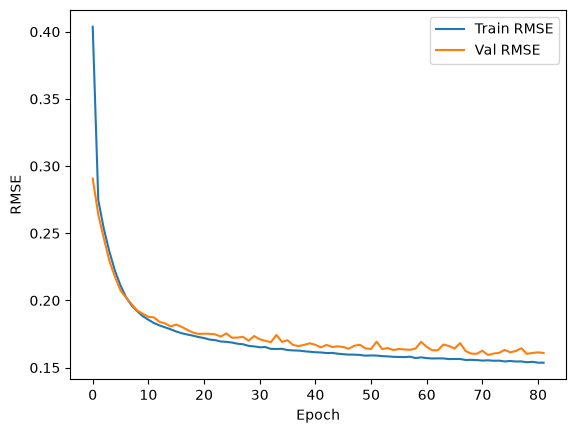

In [11]:
import matplotlib.pyplot as plt

plt.plot(history.history["RootMeanSquaredError"], label="Train RMSE")
plt.plot(history.history["val_RootMeanSquaredError"], label="Val RMSE")
plt.xlabel("Epoch")
plt.ylabel("RMSE")
plt.legend()
plt.show()

In [12]:
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

test_clean = test_set.dropna(subset=["Fire Alarm"])
X_test = test_clean.drop("Fire Alarm", axis=1)
y_test = test_clean["Fire Alarm"].values

X_test_prepared = preprocessing.transform(X_test)  

loss, rmse = model.evaluate(X_test_prepared, y_test, verbose=0)
final_r2 = r2_score(y_test, model.predict(X_test_prepared))

print("Neural Network på test data:")
print(f"MSE: {loss:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R2: {final_r2:.4f}")
final_mae = mean_absolute_error(y_test, model.predict(X_test_prepared))
print(f"MAE: {final_mae:.4f}")



  1/392 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step

128/392 ━━━━━━━━━━━━━━━━━━━━ 0s 396us/step

241/392 ━━━━━━━━━━━━━━━━━━━━ 0s 419us/step

353/392 ━━━━━━━━━━━━━━━━━━━━ 0s 428us/step

392/392 ━━━━━━━━━━━━━━━━━━━━ 0s 449us/step


Neural Network på test data:
MSE: 0.0240
RMSE: 0.1549
R2: 0.8824


... (2 outputs left out)

236/392 ━━━━━━━━━━━━━━━━━━━━ 0s 427us/step

363/392 ━━━━━━━━━━━━━━━━━━━━ 0s 416us/step

392/392 ━━━━━━━━━━━━━━━━━━━━ 0s 450us/step


MAE: 0.0659


In [13]:
def predicfunc(temperature_, humidity_, pm25_):
    sample = pd.DataFrame({
        "Temperature[C]": [temperature_],
        "Humidity[%]": [humidity_],
        "PM2.5": [np.log1p(pm25_)],
    })

    sample_prepared = preprocessing.transform(sample)  
    prediction = model.predict(sample_prepared, verbose=0)
    print(f"Forudsagt Fire Alarm: {prediction[0][0]:.2f} (0 = ingen alarm, 1 = alarm)")

predicfunc(20.0, 57.36, 0.0)


Forudsagt Fire Alarm: 0.48 (0 = ingen alarm, 1 = alarm)
